# Model changing mean and dispersion in positive responses

Positive responses can change both their expected level and relative variation. A Gamma location-scale model gives each parameter a predictor. Here sigma is the coefficient of variation: variance equals mu squared times sigma squared.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.models import GAMLSS

rng=np.random.default_rng(108)
data=pd.DataFrame({"x":rng.uniform(0,1,700)})
grid=pd.DataFrame({"x":np.linspace(0,1,180)})
mu=np.exp(.5+.6*np.sin(2*np.pi*data.x))
sigma=.2+.3*data.x
data["y"]=rng.gamma(shape=1/sigma**2,scale=mu*sigma**2)
train,test=train_test_split(data,test_size=.25,random_state=108)
model=GAMLSS(family="gamma",formula={"mu":"y ~ s(x,bs='cr',k=10)","sigma":"~ s(x,bs='cr',k=8)"}).fit(train)
parameters=model.predict(grid)


## Inspect both distribution parameters

The fitted sigma is relative spread, not the conditional standard deviation. Multiplying it by the mean gives the Gamma standard deviation.

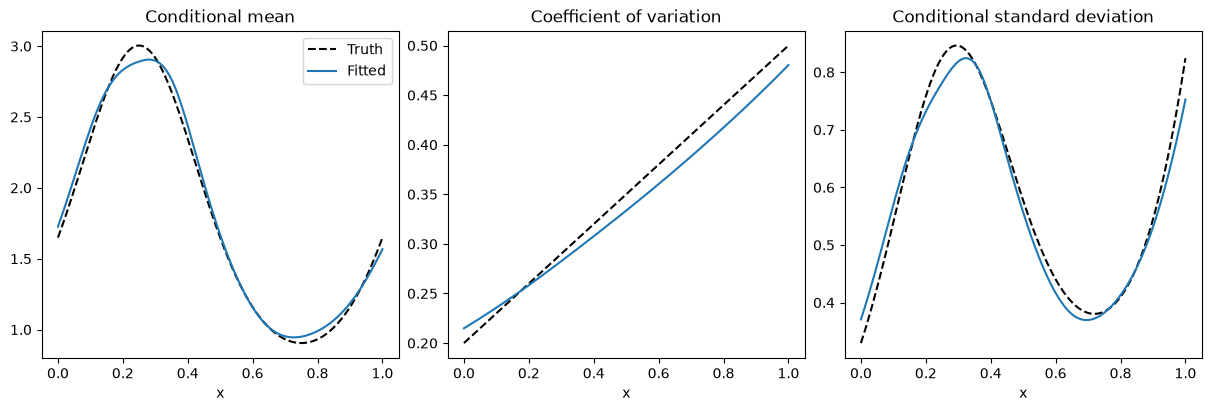

Test mean RMSE,Test negative log likelihood
0.584,0.843


In [2]:
figure,axes=plt.subplots(1,3,figsize=(12,4),constrained_layout=True)
true_mu=np.exp(.5+.6*np.sin(2*np.pi*grid.x))
true_sigma=.2+.3*grid.x
for axis,estimate,known,title in zip(axes,[parameters[:,0],parameters[:,1],parameters[:,0]*parameters[:,1]],[true_mu,true_sigma,true_mu*true_sigma],["Conditional mean","Coefficient of variation","Conditional standard deviation"]):
    axis.plot(grid.x,known,"k--",label="Truth")
    axis.plot(grid.x,estimate,label="Fitted")
    axis.set(title=title,xlabel="x")
axes[0].legend()
plt.show()
plt.close(figure)
test_parameters=model.predict(test)
pd.DataFrame({"Test mean RMSE":[mean_squared_error(test.y,test_parameters[:,0])**.5],"Test negative log likelihood":[model.evaluate(test,test.y.to_numpy())["Negative Log-Likelihood"]]}).style.hide(axis="index").format("{:.3f}")

The mean and coefficient-of-variation panels compare distinct fitted parameters with their known curves. Their product gives the conditional standard deviation, so changing absolute spread should not be read from sigma alone. Test mean RMSE is 0.584; the negative log likelihood of 0.843 assesses the fitted response distribution as well as its mean.